# 02 · Gate power: why the flywheel's three near-misses were rejected, and how many circuits a decision needs at scale

**Question.** The campaign's flywheel arm earned 0/10 promotions. In round 1 *both* arms tried the same
mutation (`chi_alloc easy32hard128`): the flywheel's CI touched zero (rejected), the control's did not
(promoted). Was the preregistered gate simply under-powered at 12 validation circuits — and if so, how
many circuits (and how much compute) does a decision need for the 3-month campaign?

**Data.** EXP-008, a post-campaign calibration experiment (TEST account, preregistered; job count and provider
status printed below): 48 *fresh* RCS circuits (generated from EXP-008's own seed, `exp008_seed` in its metadata,
not from the campaign suite; no circuit seed is shared with the suite, asserted below), the round-0 config (`uniform64`) vs the
challenger (`easy32hard128`), **two independent evaluations of each** → 96 single-evaluation paired deltas.
Source: `experiments/EXP-008-GATE-CALIBRATION/data/analysis.json` (copied byte-for-byte in the data bundle).

**Plan.** (1) Reproduce EXP-008's preregistered numbers exactly, as an anchor for our simulator.
(2) Power curve of the campaign's gate vs number of validation circuits, at four true effect sizes.
(3) Equal-budget design choices: more circuits vs repeated evaluations; a depth-stratified gate.
(4) How precisely was the gate's own threshold (`min_delta`) known? (5) What a decision costs in compute.

Everything is local `numpy` resampling — no cloud jobs. Monte Carlo sizes are stated next to each result.

**Short answer** (numbers below): partly. The χ-allocation near-misses are what a 12-circuit gate does with a real
effect of this size: it passes about half the time. The other rejections were not power failures. Reaching 80% power
at the observed effect takes several times more circuits per decision, assuming the frozen margin; a depth-stratified
gate needs fewer, but it tests a weaker hypothesis and was designed on this data.

In [1]:
import csv, json, re, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import nbcommon as C

C.style()
B = C.load_bundle()
A = B.json("experiments/EXP-008-GATE-CALIBRATION/data/analysis.json")
MIN_DELTA = A["meta"]["min_delta"]
meta = A["a1"]["circuit_meta"]
rep1 = np.array(A["a1"]["per_rep"]["rep1"]); rep2 = np.array(A["a1"]["per_rep"]["rep2"])
pooled = np.array(A["a1"]["pooled"])
depth = np.array([m["depth"] for m in meta]); nq = np.array([m["n"] for m in meta])
hard = depth >= 12                                     # campaign rule: easy d<=8, hard d>=12
print(f"circuits: {len(meta)} (n in {sorted(set(nq.tolist()))}, depth in {sorted(set(depth.tolist()))}); reps: 2; "
      f"min_delta (campaign, frozen) = {MIN_DELTA:.6f}")
print(f"mean paired Δ: rep1 {rep1.mean():+.6f} | rep2 {rep2.mean():+.6f} | pooled {pooled.mean():+.6f} "
      f"(analysis.json pooled_mean {A['a1']['pooled_mean']:+.6f})")
import csv
with open(B.path("runs/report/jobs_export.csv")) as fh:
    ledger_jobs = {r["job_name"]: r for r in csv.DictReader(fh)}
n_done = sum(ledger_jobs.get(j, {}).get("run_status") == "COMPLETED" for j in A["jobs"])
print(f"EXP-008 jobs: {A['meta']['jobs_total']} on {A['meta']['device']}; {n_done}/{len(A['jobs'])} job names resolve to "
      f"COMPLETED jobs in the campaign job export")
SUITE = B.json("suite/MANIFEST.json")["circuits"]
VAL = [c for c in SUITE if c["split"] == "val"]
# EXP-008 per-circuit seeds, by the rule in its SPEC.md: EXP008_SEED + n*100 + d*10 + i (i from the circuit id)
seeds008 = {A["meta"]["exp008_seed"] + m["n"] * 100 + m["depth"] * 10 + int(re.search(r"i(\d+)$", m["id"]).group(1))
            for m in meta}
overlap = seeds008 & {c["seed"] for c in SUITE}
assert len(seeds008) == len(meta) and not overlap
print(f"EXP-008 circuit seeds: {len(seeds008)} distinct; shared with the {len(SUITE)} campaign-suite circuit seeds: {len(overlap)}")
CHI_MAX = max(max(c["easy"], c["hard"]) for c in A["meta"]["configs"].values())

circuits: 48 (n in [20, 22, 24, 26], depth in [4, 8, 12, 16]); reps: 2; min_delta (campaign, frozen) = 0.026952
mean paired Δ: rep1 +0.036324 | rep2 +0.031456 | pooled +0.033890 (analysis.json pooled_mean +0.033890)
EXP-008 jobs: 192 on mps.cpu; 192/192 job names resolve to COMPLETED jobs in the campaign job export
EXP-008 circuit seeds: 48 distinct; shared with the 48 campaign-suite circuit seeds: 0


## 1 · Anchor: reproduce EXP-008's preregistered results exactly

A2 is the 48-circuit bootstrap CI (10 000 resamples, `default_rng(11)`); A4 is the gate's pass probability
at the campaign's 12-circuit scale (10 000 subsets via `default_rng(12)`, inner bootstrap 2 000 via
`default_rng(13)`), re-implemented from `src/gate_calib.py`. Matching them bit-for-bit shows we read EXP-008's data
and rules exactly as preregistered (both are asserted). §2 uses a separate, vectorised simulator (`pass_rate`).

In [2]:
rng = np.random.default_rng(11)
bm = pooled[rng.integers(0, 48, size=(10000, 48))].mean(axis=1)
a2 = (float(np.quantile(bm, 0.025)), float(np.quantile(bm, 0.975)))
print(f"A2 CI recomputed [{a2[0]:+.6f}, {a2[1]:+.6f}]  recorded [{A['a2']['ci_low']:+.6f}, {A['a2']['ci_high']:+.6f}]"
      f"  identical: {a2 == (A['a2']['ci_low'], A['a2']['ci_high'])}")
assert a2 == (A["a2"]["ci_low"], A["a2"]["ci_high"])

def gate_powers_exp008(vals, subsets):
    r = np.random.default_rng(13); c1 = c2 = cb = 0
    for s in subsets:
        x = vals[s]; g1 = x.mean() > MIN_DELTA
        g2 = float(np.quantile(x[r.integers(0, 12, size=(2000, 12))].mean(axis=1), 0.025)) > 0.0
        c1 += g1; c2 += g2; cb += g1 and g2
    n = len(subsets)
    return {"p_mean_gt_min_delta": float(c1 / n), "p_ci_excludes_zero": float(c2 / n), "p_both": float(cb / n)}

t0 = time.time()
sr = np.random.default_rng(12)
subsets = [sr.choice(48, size=12, replace=False) for _ in range(10000)]
a4_obs = gate_powers_exp008(pooled, subsets)
a4_shift = gate_powers_exp008(pooled + (MIN_DELTA - pooled.mean()), subsets)
print(f"A4 observed effect: {a4_obs}\n   recorded:         {A['a4']['observed']}")
print(f"A4 shifted to min_delta: {a4_shift}\n   recorded:              {A['a4']['shifted_to_min_delta']}")
print(f"identical: {a4_obs == A['a4']['observed'] and a4_shift == A['a4']['shifted_to_min_delta']}")
assert a4_obs == A["a4"]["observed"] and a4_shift == A["a4"]["shifted_to_min_delta"]

A2 CI recomputed [+0.017454, +0.052119]  recorded [+0.017454, +0.052119]  identical: True


A4 observed effect: {'p_mean_gt_min_delta': 0.6579, 'p_ci_excludes_zero': 0.6336, 'p_both': 0.5852}
   recorded:         {'p_mean_gt_min_delta': 0.6579, 'p_ci_excludes_zero': 0.6336, 'p_both': 0.5852}
A4 shifted to min_delta: {'p_mean_gt_min_delta': 0.4862, 'p_ci_excludes_zero': 0.3449, 'p_both': 0.3351}
   recorded:              {'p_mean_gt_min_delta': 0.4862, 'p_ci_excludes_zero': 0.3449, 'p_both': 0.3351}
identical: True


**Reading A4.** With an effect as large as the one actually measured (pooled Δ above), the campaign's gate passes
a 12-circuit decision only about as often as a coin flip; if the true effect sits exactly at `min_delta`, about a
third of the time (pass probabilities printed above). A4 models a random *choice* of the 12 circuits (EXP-008's
preregistered scope: circuit-subset choice, not fresh shot noise). Round 1's split verdict had a narrower cause: both
arms evaluated the same mutation on the *same* 12 circuits, so only run-to-run noise differed, and both CI lower
bounds sat at the zero boundary (notebook 01, §4, which also shows how bootstrap-seed-sensitive those verdicts were).

## 2 · Power vs number of validation circuits

**Model.** A decision draws `n` circuits with replacement from the empirical library of the **96
single-evaluation deltas** (a campaign decision compares *one* fresh candidate run against *one* stored incumbent
run, so the per-rep deltas — not the two-rep averages — carry the right noise). Effect sizes are set by shifting the
library's mean (additive-effect assumption). The gate is the campaign's fidelity rule: mean Δ > `min_delta` AND
bootstrap 95% CI excludes 0 (inner bootstrap 1 000 resamples; the campaign used 5 000). The cost gate is not simulated.
2 000 decisions per point → Monte Carlo standard error ≤ 0.011.

In [3]:
single = np.concatenate([rep1, rep2])
single_hard = np.concatenate([hard, hard])

def pass_rate(lib, n, mu=None, draws=2000, inner=1000, seed=0, chunk=100):
    """Fraction of simulated n-circuit decisions the campaign gate would PROMOTE."""
    lib = np.asarray(lib, float)
    if mu is not None:
        lib = lib - lib.mean() + mu
    r = np.random.default_rng(seed)
    passes = 0
    for start in range(0, draws, chunk):
        k = min(chunk, draws - start)
        x = lib[r.integers(0, len(lib), size=(k, n))]                  # k decisions × n circuits
        means = x.mean(axis=1)
        bi = r.integers(0, n, size=(k, inner, n))
        lo = np.quantile(np.take_along_axis(x[:, None, :].repeat(inner, 1), bi, 2).mean(axis=2), 0.025, axis=1)
        passes += int(np.sum((means > MIN_DELTA) & (lo > 0)))
    return passes / draws

NS = [12, 24, 48, 96, 192]
EFFECTS = {"no effect (μ = 0)": 0.0, "μ = min_delta": MIN_DELTA,
           f"μ = observed ({single.mean():+.4f})": float(single.mean()), "μ = 2·min_delta": 2 * MIN_DELTA}
t0 = time.time()
curve = {lab: [pass_rate(single, n, mu, seed=17 + i) for i, n in enumerate(NS)] for lab, mu in EFFECTS.items()}
print(f"simulated {len(NS) * len(EFFECTS)} points ({len(NS)} sizes × {len(EFFECTS)} effects)")
display(Markdown("| true effect | " + " | ".join(f"n={n}" for n in NS) + " |\n|---|" + "---|" * len(NS) + "\n" +
                 "\n".join(f"| {lab} | " + " | ".join(f"{p:.3f}" for p in ps) + " |" for lab, ps in curve.items())))

simulated 20 points (5 sizes × 4 effects)


| true effect | n=12 | n=24 | n=48 | n=96 | n=192 |
|---|---|---|---|---|---|
| no effect (μ = 0) | 0.015 | 0.022 | 0.003 | 0.000 | 0.000 |
| μ = min_delta | 0.324 | 0.476 | 0.494 | 0.478 | 0.483 |
| μ = observed (+0.0339) | 0.533 | 0.681 | 0.789 | 0.869 | 0.933 |
| μ = 2·min_delta | 0.947 | 0.990 | 1.000 | 1.000 | 1.000 |

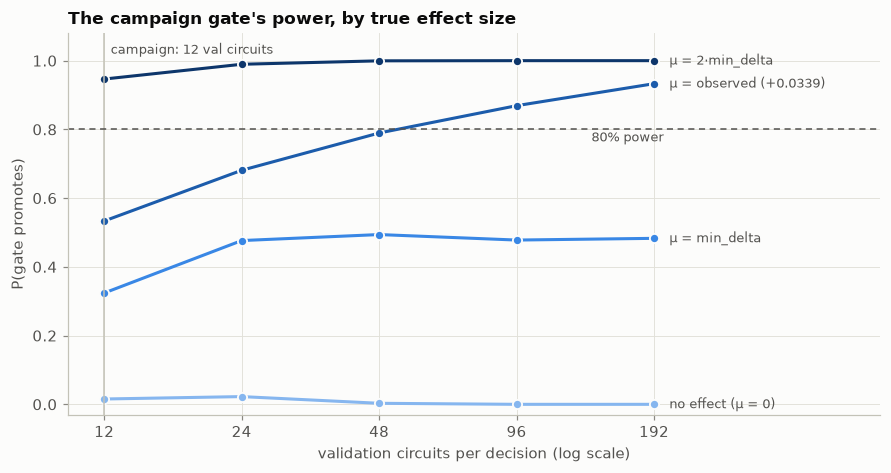

In [4]:
ramp = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]       # ordinal blue ramp (effect size is ordered)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
for (lab, ps), col in zip(curve.items(), ramp):
    ax.plot(NS, ps, "-o", color=col, ms=6, mec=C.SURFACE, mew=1.2)
    ax.text(NS[-1] * 1.08, ps[-1], lab, color=C.INK_2, fontsize=8.5, va="center")
ax.axvline(12, color=C.AXIS, lw=1); ax.text(12.4, 1.02, "campaign: 12 val circuits", fontsize=8.5, color=C.INK_2)
ax.axhline(0.8, color=C.INK_2, lw=1, ls=(0, (4, 3))); ax.text(140, 0.765, "80% power", fontsize=8.5, color=C.INK_2)
ax.set_xscale("log", base=2); ax.set_xticks(NS, [str(n) for n in NS])
ax.set_xlim(10, 600); ax.set_ylim(-0.03, 1.08)
ax.set_xlabel("validation circuits per decision (log scale)"); ax.set_ylabel("P(gate promotes)")
ax.set_title("The campaign gate's power, by true effect size")
fig.tight_layout(); plt.show()

Two properties of the preregistered gate follow directly:
- It is **conservative**: with no true effect it essentially never promotes — the right failure mode for a
  self-improvement loop, where a false promotion contaminates every later round.
- Its threshold `min_delta` is a **margin**, not a significance level: for a true effect exactly at the margin the
  pass rate cannot rise above ~½ however many circuits are used. Only effects clearly above the margin become
  reliably promotable, and only with more circuits than 12.

In [5]:
obs_lab = [k for k in curve if k.startswith("μ = observed")][0]
def first_n(ps, target=0.8):
    return next((n for n, p in zip(NS, ps) if p >= target), None)
n80_obs, n80_2x = first_n(curve[obs_lab]), first_n(curve["μ = 2·min_delta"])
display(Markdown(
    f"- At the **observed** effect, the first simulated size reaching 80% power: **n = {n80_obs if n80_obs else f'> {NS[-1]}'}** "
    f"(pass rate at n=12: {curve[obs_lab][0]:.2f}; at n=48: {curve[obs_lab][NS.index(48)]:.2f}).\n"
    f"- At **2·min_delta**: **{n80_2x if n80_2x else f'> {NS[-1]}'}** circuits (n=12: {curve['μ = 2·min_delta'][0]:.2f}).\n"
    f"- False-promotion rate with no effect, worst over n: **{max(curve['no effect (μ = 0)']):.3f}**."))

- At the **observed** effect, the first simulated size reaching 80% power: **n = 96** (pass rate at n=12: 0.53; at n=48: 0.79).
- At **2·min_delta**: **12** circuits (n=12: 0.95).
- False-promotion rate with no effect, worst over n: **0.022**.

## 3 · Spending a fixed job budget better

A decision's cost is its number of candidate jobs J. Two ways to spend J:
**(A)** J circuits × 1 evaluation (the campaign's design) or **(B)** J/2 circuits × 2 evaluations, averaged.
EXP-008 measured both directly: (A) draws from the 96 single-evaluation deltas, (B) from the 48 two-rep averages.

The per-circuit deltas are also strongly **depth-structured** — the χ reallocation trades a little fidelity on
shallow circuits (χ 64→32) for a lot on deep ones (χ 64→128):

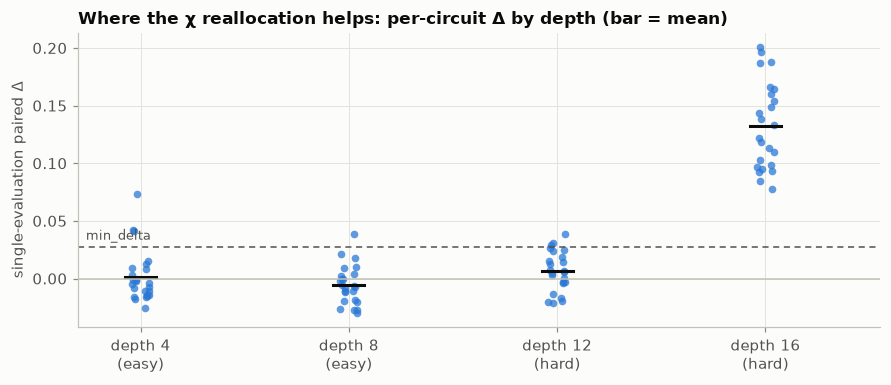

depth  4: mean Δ +0.0015  sd 0.0227  (12 circuits × 2 evals)
depth  8: mean Δ -0.0054  sd 0.0168  (12 circuits × 2 evals)
depth 12: mean Δ +0.0068  sd 0.0173  (12 circuits × 2 evals)
depth 16: mean Δ +0.1327  sd 0.0380  (12 circuits × 2 evals)


In [6]:
fig, ax = plt.subplots(figsize=(8.2, 3.6))
rs = np.random.default_rng(5)
for d in sorted(set(depth)):
    m = depth == d
    for vals, dx in ((rep1[m], -0.12), (rep2[m], 0.12)):
        ax.plot(d + dx + rs.uniform(-0.05, 0.05, m.sum()), vals, "o", ms=5, color=C.BLUE, alpha=0.75, mec="none")
    ax.plot([d - 0.3, d + 0.3], [np.r_[rep1[m], rep2[m]].mean()] * 2, color=C.INK, lw=2)
ax.axhline(0, color=C.AXIS, lw=1)
ax.axhline(MIN_DELTA, color=C.INK_2, lw=1, ls=(0, (4, 3)))
ax.text(2.95, MIN_DELTA + 0.004, "min_delta", fontsize=8.5, color=C.INK_2, va="bottom")
ax.set_xticks(sorted(set(depth)), [f"depth {d}\n({'easy' if d <= 8 else 'hard'})" for d in sorted(set(depth))])
ax.set_xlim(2.8, 18.2)
ax.set_ylabel("single-evaluation paired Δ")
ax.set_title("Where the χ reallocation helps: per-circuit Δ by depth (bar = mean)")
fig.tight_layout(); plt.show()
for d in sorted(set(depth)):
    m = depth == d
    v = np.r_[rep1[m], rep2[m]]
    print(f"depth {d:2d}: mean Δ {v.mean():+.4f}  sd {v.std(ddof=1):.4f}  ({m.sum()} circuits × 2 evals)")

A **depth-stratified gate** uses that structure instead of averaging it away: spend J/2 jobs on hard circuits and J/2
on easy ones, and promote only if (hard stratum: mean Δ > `min_delta` AND CI excludes 0) AND (easy stratum: CI lower
bound > −`min_delta`, i.e. non-inferior within the same margin). It asks the question the mutation actually poses —
*does reallocating χ help where truncation binds without hurting elsewhere?*

**Caveat (stated up front):** this gate is designed *after* looking at EXP-008, and is evaluated on the same data, so
its power below is optimistic and hypothesis-generating; a fresh preregistered calibration would have to confirm it.
Its false-promotion rate is checked by shifting **both** strata to zero effect.

In [7]:
def strat_pass(n_total, mu_shift=None, draws=2000, inner=1000, seed=0, mu_split=None):
    """Stratified gate on single-evaluation deltas; mu_shift=0 centres both strata at 0 (null);
    mu_split=(mu_hard, mu_easy) centres the two strata separately (mixed scenario)."""
    h, e = single[single_hard], single[~single_hard]
    if mu_shift is not None:
        h, e = h - h.mean() + mu_shift, e - e.mean() + mu_shift
    if mu_split is not None:
        h, e = h - h.mean() + mu_split[0], e - e.mean() + mu_split[1]
    r = np.random.default_rng(seed); k = n_total // 2; ok = 0
    for _ in range(draws):
        xh, xe = h[r.integers(0, len(h), k)], e[r.integers(0, len(e), k)]
        loh = np.quantile(xh[r.integers(0, k, (inner, k))].mean(1), 0.025)
        loe = np.quantile(xe[r.integers(0, k, (inner, k))].mean(1), 0.025)
        ok += (xh.mean() > MIN_DELTA) and (loh > 0) and (loe > -MIN_DELTA)
    return ok / draws

JS = [12, 24, 48, 96]
t0 = time.time()
designA = [pass_rate(single, J, None, seed=31 + i) for i, J in enumerate(JS)]
designB = [pass_rate(pooled, J // 2, None, seed=41 + i) for i, J in enumerate(JS)]
designS = [strat_pass(J, None, seed=51 + i) for i, J in enumerate(JS)]
nullS = [strat_pass(J, 0.0, seed=61 + i) for i, J in enumerate(JS)]
nullA = [pass_rate(single, J, 0.0, seed=71 + i) for i, J in enumerate(JS)]
MIX = (2 * MIN_DELTA, -0.9 * MIN_DELTA)            # hard stratum gains, easy stratum loses (within the S margin)
h_, e_ = single[single_hard], single[~single_hard]
lib_mix = np.r_[h_ - h_.mean() + MIX[0], e_ - e_.mean() + MIX[1]]
mix_overall = lib_mix.mean() / MIN_DELTA
mixA = [pass_rate(lib_mix, J, None, seed=81 + i) for i, J in enumerate(JS)]
mixS = [strat_pass(J, None, seed=91 + i, mu_split=MIX) for i, J in enumerate(JS)]
display(Markdown("At the observed effect (2 000 simulated decisions per cell; design A repeats §2 with independent draws, so differences of ~0.01–0.02 from §2 are Monte Carlo noise):\n\n| design (J candidate jobs per decision) | " +
                 " | ".join(f"J={J}" for J in JS) + " |\n|---|" + "---|" * len(JS) + "\n" +
                 f"| (A) J circuits × 1 eval — campaign design | " + " | ".join(f"{p:.3f}" for p in designA) + " |\n" +
                 f"| (B) J/2 circuits × 2 evals, averaged | " + " | ".join(f"{p:.3f}" for p in designB) + " |\n" +
                 f"| (S) depth-stratified gate, J/2 + J/2 | " + " | ".join(f"{p:.3f}" for p in designS) + " |\n" +
                 f"| (A) false promotions, no effect | " + " | ".join(f"{p:.3f}" for p in nullA) + " |\n" +
                 f"| (S) false promotions, no effect in either stratum | " + " | ".join(f"{p:.3f}" for p in nullS) + " |\n" +
                 f"| (A) mixed: hard +2·min_delta, easy −0.9·min_delta (overall {mix_overall:.2f}·min_delta) | " +
                 " | ".join(f"{p:.3f}" for p in mixA) + " |\n" +
                 f"| (S) same mixed scenario | " + " | ".join(f"{p:.3f}" for p in mixS) + " |"))
display(Markdown(
    f"**S tests a different, weaker hypothesis than A.** In the mixed scenario the overall gain is "
    f"{mix_overall:.2f}·`min_delta`, below the campaign's bar. As J grows, A promotes it less often "
    f"({mixA[0]:.0%} at J = {JS[0]} → {mixA[-1]:.0%} at J = {JS[-1]}) while S promotes it more often ({mixS[0]:.0%} → "
    f"{mixS[-1]:.0%}): S only asks whether the change helps where truncation binds without hurting elsewhere by more "
    f"than the margin. Preregistering S means preregistering that hypothesis, not just a more powerful test."))

At the observed effect (2 000 simulated decisions per cell; design A repeats §2 with independent draws, so differences of ~0.01–0.02 from §2 are Monte Carlo noise):

| design (J candidate jobs per decision) | J=12 | J=24 | J=48 | J=96 |
|---|---|---|---|---|
| (A) J circuits × 1 eval — campaign design | 0.547 | 0.683 | 0.773 | 0.868 |
| (B) J/2 circuits × 2 evals, averaged | 0.340 | 0.559 | 0.680 | 0.780 |
| (S) depth-stratified gate, J/2 + J/2 | 0.828 | 0.982 | 1.000 | 1.000 |
| (A) false promotions, no effect | 0.017 | 0.020 | 0.003 | 0.000 |
| (S) false promotions, no effect in either stratum | 0.043 | 0.033 | 0.024 | 0.004 |
| (A) mixed: hard +2·min_delta, easy −0.9·min_delta (overall 0.55·min_delta) | 0.107 | 0.150 | 0.104 | 0.040 |
| (S) same mixed scenario | 0.038 | 0.060 | 0.086 | 0.150 |

**S tests a different, weaker hypothesis than A.** In the mixed scenario the overall gain is 0.55·`min_delta`, below the campaign's bar. As J grows, A promotes it less often (11% at J = 12 → 4% at J = 96) while S promotes it more often (4% → 15%): S only asks whether the change helps where truncation binds without hurting elsewhere by more than the margin. Preregistering S means preregistering that hypothesis, not just a more powerful test.

## 4 · How precisely was the gate's threshold known?

`min_delta` = 2 × sd of the paired differences between two *identical* baseline runs on the 12 val circuits (G3).
An sd estimated from 12 pairs has a wide confidence interval (χ² interval, 11 degrees of freedom). EXP-008 provides
an independent estimate of the same quantity: the same baseline config run twice on 48 fresh circuits.

In [8]:
from scipy import stats
g3 = next(B.json(f"runs/flywheel/{p.name}/metrics.json") for p in sorted(B.path("runs/flywheel").iterdir())
          if p.name.endswith("_g3"))
d12 = np.array([a["xeb"] - b["xeb"] for a, b in zip(g3["val_run1"]["rows"], g3["val_run2"]["rows"])])
sd12, df = d12.std(ddof=1), len(d12) - 1
ci_sd = (sd12 * np.sqrt(df / stats.chi2.ppf(0.975, df)), sd12 * np.sqrt(df / stats.chi2.ppf(0.025, df)))
jobs = A["jobs"]
def xeb_of(cfg, rep):
    return np.array([jobs[f"exp008-{cfg}-q{m['n']}d{m['depth']}i{m['id'][-1]}-rep{rep}"]["xeb"] for m in meta])
base_diff = xeb_of("base", 1) - xeb_of("base", 2)
chal_diff = xeb_of("chal", 1) - xeb_of("chal", 2)
assert np.allclose(np.abs(base_diff), A["a3"]["base"]["abs_rep_diff"])          # matches EXP-008 A3
print(f"campaign G3 (12 pairs): sd {sd12:.5f}, 95% CI [{ci_sd[0]:.5f}, {ci_sd[1]:.5f}] -> min_delta range "
      f"[{2*ci_sd[0]:.4f}, {2*ci_sd[1]:.4f}] (frozen value {MIN_DELTA:.4f})")
print(f"EXP-008 baseline, 48 fresh circuits: sd {base_diff.std(ddof=1):.5f}; challenger: sd {chal_diff.std(ddof=1):.5f}")
print(f"  -> 2·sd on 48 circuits: baseline {2*base_diff.std(ddof=1):.4f}, challenger {2*chal_diff.std(ddof=1):.4f}")

campaign G3 (12 pairs): sd 0.01348, 95% CI [0.00955, 0.02288] -> min_delta range [0.0191, 0.0458] (frozen value 0.0270)
EXP-008 baseline, 48 fresh circuits: sd 0.01620; challenger: sd 0.01731
  -> 2·sd on 48 circuits: baseline 0.0324, challenger 0.0346


## 5 · What a decision costs

Server-side run time of each EXP-008 job as recorded by the platform (`run_time_ms` in the job export),
by circuit width/depth class and bond dimension χ. This prices the designs above in job-minutes.

In [9]:
rows = [r for r in csv.DictReader(open(B.path("runs/report/jobs_export.csv")))
        if r["exp_id"] == "EXP-008-GATE-CALIBRATION"]
cell = {}
for r in rows:
    q, d = map(int, re.search(r"q(\d+)d(\d+)", r["job_name"]).groups())
    chi = json.loads(r["options"])["mps_bond_dimension"]
    cell.setdefault((q, "easy" if d <= 8 else "hard", chi), []).append(int(r["run_time_ms"]) / 60000)
tab = "| n | class | χ | jobs | mean run min | max run min |\n|---|---|---|---|---|---|\n" + "\n".join(
    f"| {q} | {c} | {chi} | {len(v)} | {np.mean(v):.2f} | {np.max(v):.2f} |" for (q, c, chi), v in sorted(cell.items()))
display(Markdown(tab))
chal_min = [int(r["run_time_ms"]) / 60000 for r in rows if "-chal-" in r["job_name"]]
per_job = float(np.mean(chal_min))
print(f"challenger config: mean {per_job:.2f} server-minutes per job over {len(chal_min)} jobs")
for J in JS:
    print(f"  decision with J={J:3d} candidate jobs ≈ {J * per_job:6.1f} job-minutes "
          f"(≈ {J * per_job / 60:.1f} job-hours; parallel across workers)")

| n | class | χ | jobs | mean run min | max run min |
|---|---|---|---|---|---|
| 20 | easy | 32 | 12 | 1.58 | 1.71 |
| 20 | easy | 64 | 12 | 1.85 | 2.28 |
| 20 | hard | 64 | 12 | 2.10 | 2.30 |
| 20 | hard | 128 | 12 | 2.20 | 2.40 |
| 22 | easy | 32 | 12 | 1.76 | 1.91 |
| 22 | easy | 64 | 12 | 1.91 | 2.53 |
| 22 | hard | 64 | 12 | 2.23 | 2.55 |
| 22 | hard | 128 | 12 | 2.46 | 2.65 |
| 24 | easy | 32 | 12 | 1.93 | 2.09 |
| 24 | easy | 64 | 12 | 2.11 | 2.79 |
| 24 | hard | 64 | 12 | 2.48 | 2.82 |
| 24 | hard | 128 | 12 | 2.71 | 2.93 |
| 26 | easy | 32 | 12 | 2.17 | 2.34 |
| 26 | easy | 64 | 12 | 2.31 | 3.05 |
| 26 | hard | 64 | 12 | 2.70 | 3.08 |
| 26 | hard | 128 | 12 | 3.21 | 3.41 |

challenger config: mean 2.25 server-minutes per job over 96 jobs
  decision with J= 12 candidate jobs ≈   27.0 job-minutes (≈ 0.5 job-hours; parallel across workers)
  decision with J= 24 candidate jobs ≈   54.1 job-minutes (≈ 0.9 job-hours; parallel across workers)
  decision with J= 48 candidate jobs ≈  108.1 job-minutes (≈ 1.8 job-hours; parallel across workers)
  decision with J= 96 candidate jobs ≈  216.3 job-minutes (≈ 3.6 job-hours; parallel across workers)


## Implications for the 3-month campaign

In [10]:
iA = JS.index(48)
RJ = B.json("runs/report/rounds.json")
fw = sorted([r for r in RJ if r["arm"] == "flywheel"], key=lambda r: r["round"])
chi_fw = [r for r in fw if r["family"] == "chi_alloc"]
perm_fw = [r for r in fw if r["family"] == "permutation" and r["round"] != 4]
r4_fw = next(r for r in fw if r["round"] == 4)
shot_fw = [r for r in fw if r["family"] == "shots_alloc"]
display(Markdown(f"""
1. **The flywheel's near-misses were a power problem; its other rejections were not.** Its {len(chi_fw)} χ-allocation
   candidates (rounds {", ".join(str(r['round']) for r in chi_fw)}) cleared the mean bar but not the CI bar, and at 12
   validation circuits the preregistered gate promotes a real effect of the measured size with probability
   ≈ {a4_obs['p_both']:.2f} (EXP-008 A4, two-rep averages; ≈ {curve[obs_lab][0]:.2f} with single-evaluation noise, §2).
   Its {len(perm_fw)} valid permutation candidates lost {-max(r['mean_delta'] for r in perm_fw):.2f}–{-min(r['mean_delta'] for r in perm_fw):.2f} XEB
   (round 4's {r4_fw['mean_delta']:+.2f} is the since-fixed scoring-bug row). Its {len(shot_fw)} shot-allocation candidates
   showed no fidelity change ({"; ".join(f"Δ {r['mean_delta']:+.4f}, CI [{r['ci'][0]:+.4f}, {r['ci'][1]:+.4f}], cost ratio {r['cost_ratio']:.3f}" for r in shot_fw)}):
   moving shots between circuits cannot raise expected linear XEB, whose estimator is unbiased in the shot count, so a
   fidelity-first gate can promote such cost-only changes only by noise. The power analysis says nothing about proposal
   quality.
2. **The gate's conservatism is worth keeping.** No-effect false-promotion rates stay at or below
   {max(curve['no effect (μ = 0)'] + nullA):.3f} for the campaign design across every simulated size
   (the stratified variant below: at most {max(nullS):.3f}).
3. **Scale the decision, not just the loop.** With the campaign design, 80% power at the observed effect needs
   {f'between 48 and {n80_obs}' if n80_obs == 96 else (str(n80_obs) if n80_obs else f'more than {NS[-1]}')} validation circuits per decision (first simulated size above 80%: {n80_obs}). At J = 48 jobs the three
   designs promote the observed effect with probability (A) {designA[iA]:.2f}, (B) {designB[iA]:.2f},
   (S) {designS[iA]:.2f}, with no-effect false-promotion rates (A) {nullA[iA]:.3f} and (S) {nullS[iA]:.3f}. Repeating evaluations
   (B) buys less than adding circuits. The stratified gate (S) is a candidate to preregister, but it tests a weaker
   hypothesis (at J = {JS[-1]} it promotes the mixed scenario in {mixS[-1]:.2f} of decisions, A in {mixA[-1]:.2f}), and it was designed on
   this data, so both the hypothesis and the gate must be fixed in advance and confirmed on fresh circuits.
4. **Re-estimate the threshold at scale.** The frozen `min_delta` came from 12 pairs; its 95% range spans
   [{2*ci_sd[0]:.4f}, {2*ci_sd[1]:.4f}]. EXP-008's 48-circuit estimate gives {2*base_diff.std(ddof=1):.4f} (baseline config) — inside that
   range, on a library that also contains depth-{"/".join(map(str, sorted(set(depth.tolist()) - {c["depth"] for c in VAL})))} and {"/".join(map(str, sorted(set(nq.tolist()) - {c["n"] for c in VAL})))}-qubit circuits (absent from the {len(VAL)} val circuits). The power figures above assume the frozen
   `min_delta` ({MIN_DELTA:.4f}); with EXP-008's estimate the observed effect ({pooled.mean():+.4f}) sits
   {"just above" if pooled.mean() > 2*base_diff.std(ddof=1) else "below"} the margin, where power grows only slowly with n
   (at an effect equal to the margin it saturates near ½, §2). The scale-up must preregister the margin as a minimum effect of interest,
   separately from the noise calibration.
5. **Compute.** At ≈ {per_job:.1f} server-minutes per `mps.cpu` job ({nq.min()}–{nq.max()} qubits, χ ≤ {CHI_MAX}), a J = 48 decision costs
   ≈ {48 * per_job / 60:.1f} job-hours at this circuit size, and the jobs are independent, so they parallelise. Costs at
   larger width or χ must be measured, not extrapolated from these.
"""))


1. **The flywheel's near-misses were a power problem; its other rejections were not.** Its 3 χ-allocation
   candidates (rounds 1, 2, 3) cleared the mean bar but not the CI bar, and at 12
   validation circuits the preregistered gate promotes a real effect of the measured size with probability
   ≈ 0.59 (EXP-008 A4, two-rep averages; ≈ 0.53 with single-evaluation noise, §2).
   Its 4 valid permutation candidates lost 0.43–0.54 XEB
   (round 4's -0.93 is the since-fixed scoring-bug row). Its 2 shot-allocation candidates
   showed no fidelity change (Δ -0.0008, CI [-0.0116, +0.0098], cost ratio 0.896; Δ -0.0106, CI [-0.0237, +0.0027], cost ratio 0.818):
   moving shots between circuits cannot raise expected linear XEB, whose estimator is unbiased in the shot count, so a
   fidelity-first gate can promote such cost-only changes only by noise. The power analysis says nothing about proposal
   quality.
2. **The gate's conservatism is worth keeping.** No-effect false-promotion rates stay at or below
   0.022 for the campaign design across every simulated size
   (the stratified variant below: at most 0.043).
3. **Scale the decision, not just the loop.** With the campaign design, 80% power at the observed effect needs
   between 48 and 96 validation circuits per decision (first simulated size above 80%: 96). At J = 48 jobs the three
   designs promote the observed effect with probability (A) 0.77, (B) 0.68,
   (S) 1.00, with no-effect false-promotion rates (A) 0.003 and (S) 0.024. Repeating evaluations
   (B) buys less than adding circuits. The stratified gate (S) is a candidate to preregister, but it tests a weaker
   hypothesis (at J = 96 it promotes the mixed scenario in 0.15 of decisions, A in 0.04), and it was designed on
   this data, so both the hypothesis and the gate must be fixed in advance and confirmed on fresh circuits.
4. **Re-estimate the threshold at scale.** The frozen `min_delta` came from 12 pairs; its 95% range spans
   [0.0191, 0.0458]. EXP-008's 48-circuit estimate gives 0.0324 (baseline config) — inside that
   range, on a library that also contains depth-4 and 22-qubit circuits (absent from the 12 val circuits). The power figures above assume the frozen
   `min_delta` (0.0270); with EXP-008's estimate the observed effect (+0.0339) sits
   just above the margin, where power grows only slowly with n
   (at an effect equal to the margin it saturates near ½, §2). The scale-up must preregister the margin as a minimum effect of interest,
   separately from the noise calibration.
5. **Compute.** At ≈ 2.3 server-minutes per `mps.cpu` job (20–26 qubits, χ ≤ 128), a J = 48 decision costs
   ≈ 1.8 job-hours at this circuit size, and the jobs are independent, so they parallelise. Costs at
   larger width or χ must be measured, not extrapolated from these.
